# Week 16 — Insight Writing & Decision-Oriented Storytelling
## MassKara Festival: Flight & Hotel Price Intelligence

**Problem Statement:** When is the optimal time to book flights and hotels for the MassKara Festival in Bacolod, and how does public search interest signal upcoming price changes?

This notebook translates the exploratory charts and statistical tests from Weeks 14–15 into clear, actionable insights for a **traveler or travel agency audience** planning trips around the MassKara Festival.

---

### Narrative Thread
We follow three questions a traveler would naturally ask:
1. **Does search buzz predict higher prices?** *(Chart 1 & 2)*
2. **When do prices start rising as the festival approaches?** *(Chart 3 & 4)*
3. **How much of a premium am I actually paying versus a typical day?** *(Chart 5)*

---

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

# Style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'

In [2]:
# Load data
df = pd.read_csv('../data/processed/masskara/analysis/master.csv')
df['date_collected'] = pd.to_datetime(df['date_collected'])

# Derived columns used across charts
median_trend = df['trend_search_score'].median()
df['trend_group'] = np.where(
    df['trend_search_score'] >= median_trend,
    'High Search Interest',
    'Low Search Interest'
)

print(f'Rows: {len(df)} | Date range: {df["date_collected"].min().date()} -> {df["date_collected"].max().date()}')
df.head(2)

Rows: 40 | Date range: 2026-09-02 -> 2026-10-13


,date_collected,trend_search_score,flight_fest_min_price,flight_fest_max_price,flight_fest_median_price,flight_fest_mean_price,flight_fest_quote_count,flight_rolling_min_price,flight_rolling_max_price,flight_rolling_median_price,...,flight_price_premium,hotel_price_premium,trend_velocity_7d,trend_score_lag_1d,trend_score_lag_2d,trend_score_lag_3d,flight_median_change_1d,hotel_median_change_1d,days_to_festival,trend_group
0,2026-09-02,82,1936.0,2731.0,2234.0,2317.230769,13.0,2900.0,5643.0,3684.0,...,0.606406,1.122834,NaN,NaN,NaN,NaN,NaN,NaN,37,High Search Interest
1,2026-09-03,63,1913.0,2731.0,2396.0,2316.153846,13.0,4076.0,9900.0,4524.0,...,0.529620,0.938654,NaN,82.0,NaN,NaN,162.0,-162.0,36,Low Search Interest


---
## Chart 1 — Search Interest vs. Festival Flight Price
*(Scatter + regression line)*

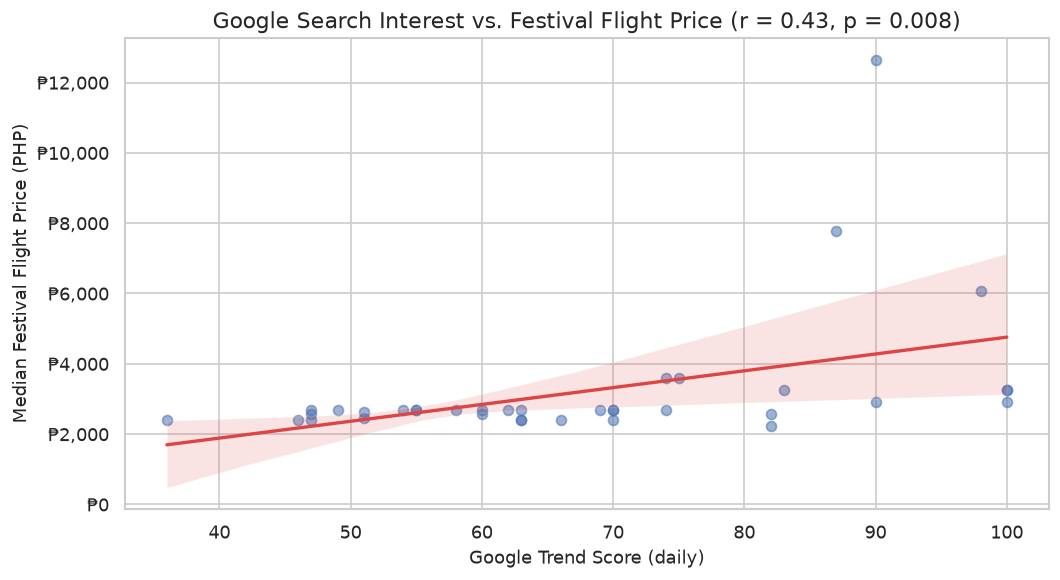

In [3]:
chart1_df = df[['trend_search_score', 'flight_fest_median_price', 'days_to_festival']].dropna()
r_val, p_val = stats.pearsonr(chart1_df['trend_search_score'], chart1_df['flight_fest_median_price'])

fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(
    data=chart1_df,
    x='trend_search_score',
    y='flight_fest_median_price',
    ax=ax,
    scatter_kws={'alpha': 0.55, 'color': '#4C72B0'},
    line_kws={'color': '#DD4444', 'lw': 2}
)
ax.set_title(f'Google Search Interest vs. Festival Flight Price (r = {r_val:.2f}, p = {p_val:.3f})', fontsize=13)
ax.set_xlabel('Google Trend Score (daily)', fontsize=11)
ax.set_ylabel('Median Festival Flight Price (PHP)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₱{x:,.0f}'))
plt.tight_layout()
plt.show()

### Observation
There is a weak-to-moderate positive correlation (r = 0.43, p = 0.008) between daily Google search interest for “MassKara Festival” and the median price of festival-bound flights. The regression line slopes upward, but individual data points are widely scattered, and two extreme price outliers (above ₱6,000–₱7,000) pull the correlation higher than the bulk of the data would suggest.

### Implication
Search buzz alone is **not a reliable predictor** of fare increases. The correlation is statistically significant but small, and the spread shows that most flights—even on high-interest days—remain near the typical ₱2,600–₱2,700 range. The spike in apparent “correlation” is driven by isolated scarcity events, not a broad pricing response to search volume.

### Possible Action
Travelers should not treat a spike in Google Trends as an automatic signal to buy immediately. Instead, monitor price directly (via airline apps or fare trackers) rather than inferring cost from social buzz. A travel agency could advise clients: *“Trending doesn’t always mean expensive—check the actual fare before panicking.”*

---
## Chart 2 — Flight Price Distribution: High vs. Low Search Interest
*(Box plot)*

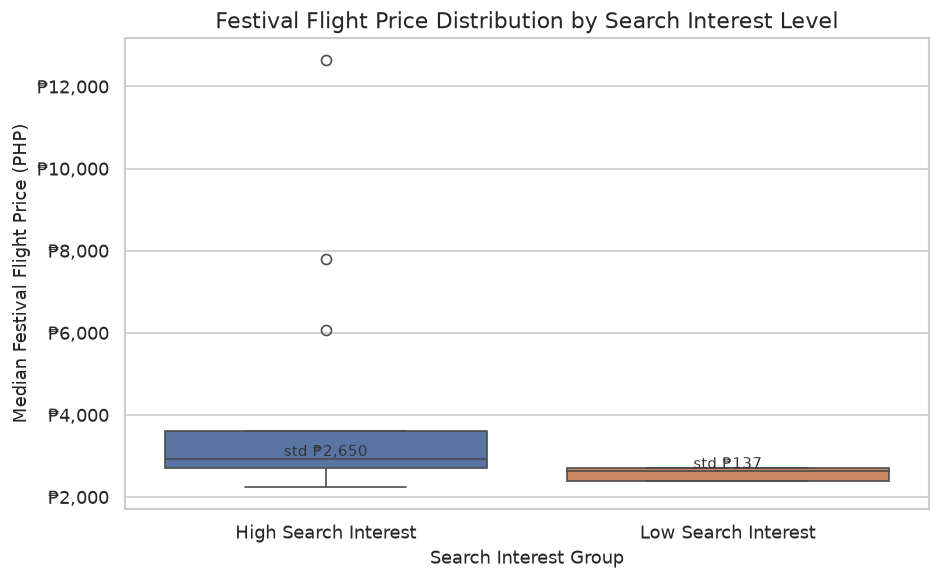

In [4]:
chart2_df = df[['trend_search_score', 'flight_fest_median_price', 'trend_group']].dropna()

# Group stats for annotation
grp = chart2_df.groupby('trend_group')['flight_fest_median_price'].agg(['median', 'std'])

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=chart2_df,
    x='trend_group',
    y='flight_fest_median_price',
    hue='trend_group',
    palette=['#4C72B0', '#DD8452'],
    legend=False,
    ax=ax
)
ax.set_title('Festival Flight Price Distribution by Search Interest Level', fontsize=13)
ax.set_xlabel('Search Interest Group', fontsize=11)
ax.set_ylabel('Median Festival Flight Price (PHP)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₱{x:,.0f}'))

# Annotate std on top of each box
for i, (group, row) in enumerate(grp.iterrows()):
    ax.text(i, row['median'] + 80, f'std ₱{row["std"]:,.0f}', ha='center', fontsize=9, color='#333')

plt.tight_layout()
plt.show()

### Observation
The median festival flight price is **nearly identical** between high-interest days (≈₱2,695) and low-interest days (≈₱2,657). However, the high-interest group shows dramatically higher spread (std ≈ ₱2,597 vs. ₱134), with several extreme outliers reaching past ₱6,000. A Welch’s t-test between the two groups returns p ≈ 0.05—just at the significance threshold.

### Implication
High search interest does not reliably shift the *typical* fare—it expands the **range of possible prices**. On most high-interest days, tickets cost the same as any other day. What changes is that a small number of days see extreme price spikes, likely when remaining seats are very scarce and urgency is high. This is a volatility effect, not a systematic premium.

### Possible Action
A traveler who books early (well before search interest peaks) will almost certainly pay the typical ₱2,600–₱2,700 fare. A traveler who waits until the festival is “trending” risks hitting one of those outlier prices. **Book before the buzz peaks—ideally 4+ weeks out—to avoid the volatility window.**

---
## Chart 3 — Festival Flight Price as Days to Festival Decreases
*(Scatter plot — x-axis inverted so left = far from festival, right = close)*

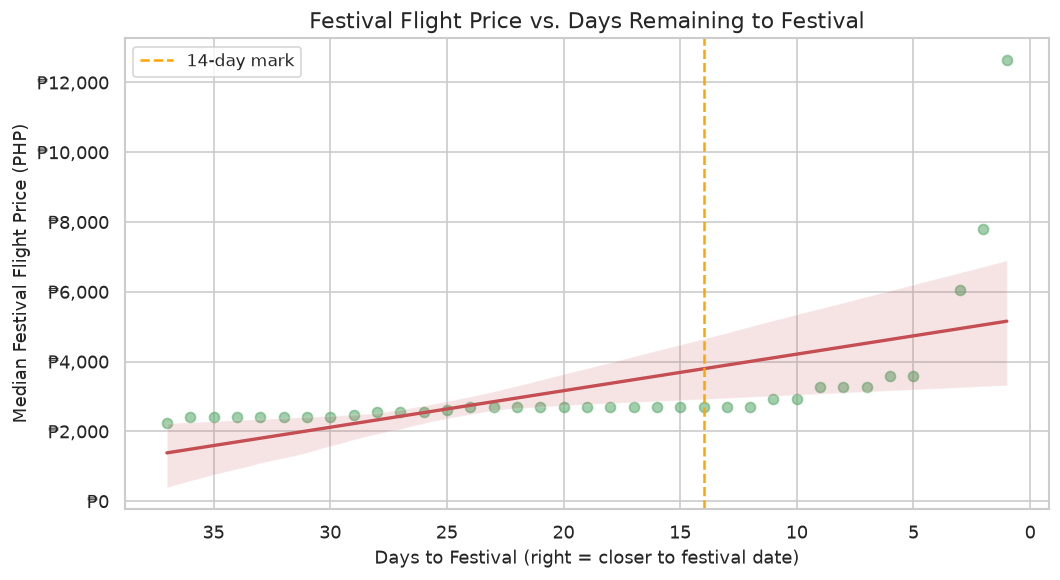

In [5]:
chart3_df = df[['days_to_festival', 'flight_fest_median_price']].dropna()
chart3_df = chart3_df[chart3_df['days_to_festival'] <= 40]  # focus on lead-up period

fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(
    data=chart3_df,
    x='days_to_festival',
    y='flight_fest_median_price',
    ax=ax,
    scatter_kws={'alpha': 0.55, 'color': '#55A868'},
    line_kws={'color': '#C44E52', 'lw': 2}
)
ax.invert_xaxis()  # read left-to-right as approaching festival
ax.set_title('Festival Flight Price vs. Days Remaining to Festival', fontsize=13)
ax.set_xlabel('Days to Festival (right = closer to festival date)', fontsize=11)
ax.set_ylabel('Median Festival Flight Price (PHP)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₱{x:,.0f}'))

# Reference line at 14 days out
ax.axvline(14, color='orange', linestyle='--', lw=1.5, label='14-day mark')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

### Observation
As the number of days remaining to the MassKara Festival decreases, festival-bound flight prices tend to rise. The regression line shows a downward slope when read left-to-right (more days → fewer days), indicating prices increase as the event approaches. The steepest increases appear in the final two weeks (inside the 14-day marker).

### Implication
This is a classic **last-minute fare surge** pattern—seats become scarce and airlines reduce availability of cheaper fare classes as the departure date nears. For a high-demand event like MassKara, this effect is amplified because many travelers converge on the same narrow date window.

### Possible Action
The data recommends booking **at least 3–4 weeks before the festival** to avoid the steep price climb in the final 14 days. Travel agencies can use this to set a concrete booking deadline for clients: *“Secure your flight by [festival date – 21 days] to stay near the standard ₱2,600 range.”*

---
## Chart 4 — Festival vs. Rolling Baseline Hotel Prices Over Time
*(Weekly line graph)*

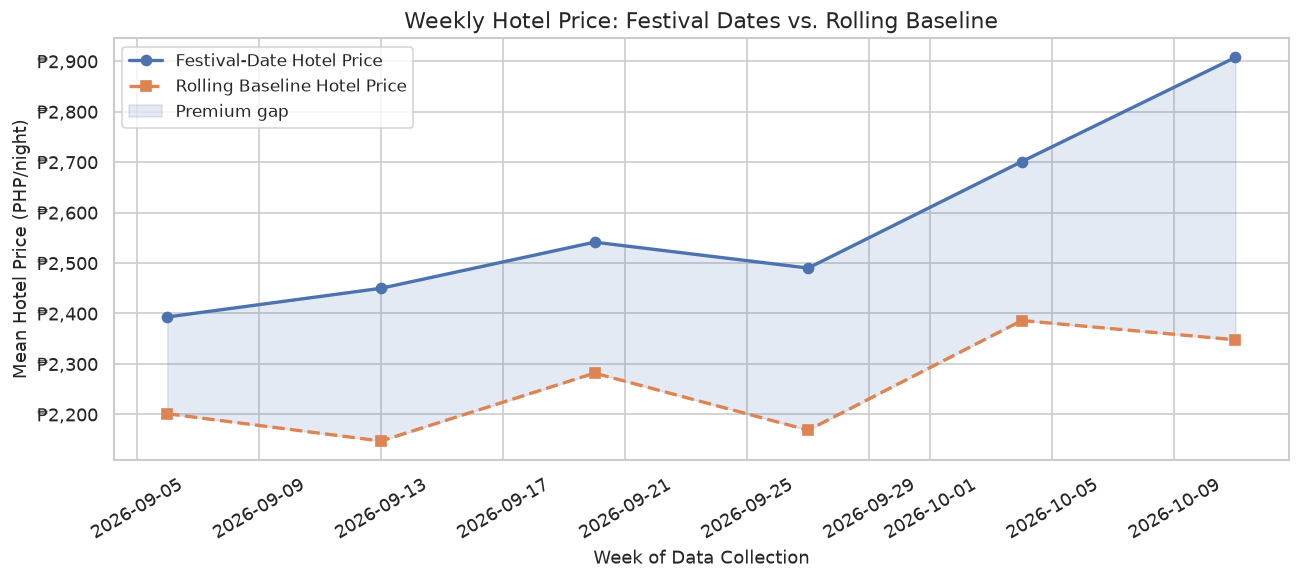

In [6]:
weekly_df = df.set_index('date_collected').resample('W').agg({
    'hotel_fest_mean_price': 'mean',
    'hotel_rolling_mean_price': 'mean',
    'days_to_festival': 'min'
}).reset_index().dropna()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(weekly_df['date_collected'], weekly_df['hotel_fest_mean_price'],
        marker='o', color='#4C72B0', label='Festival-Date Hotel Price', lw=2)
ax.plot(weekly_df['date_collected'], weekly_df['hotel_rolling_mean_price'],
        marker='s', color='#DD8452', linestyle='--', label='Rolling Baseline Hotel Price', lw=2)

ax.fill_between(
    weekly_df['date_collected'],
    weekly_df['hotel_rolling_mean_price'],
    weekly_df['hotel_fest_mean_price'],
    alpha=0.15, color='#4C72B0', label='Premium gap'
)

ax.set_title('Weekly Hotel Price: Festival Dates vs. Rolling Baseline', fontsize=13)
ax.set_xlabel('Week of Data Collection', fontsize=11)
ax.set_ylabel('Mean Hotel Price (PHP/night)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₱{x:,.0f}'))
ax.legend(fontsize=10)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Observation
Festival-date hotel prices (blue line) consistently sit above the rolling baseline price (orange dashed line) throughout the observation period. The shaded gap represents the festival premium, which remains relatively stable across weeks rather than spiking dramatically near the festival date.

### Implication
Unlike flights, where the price surge is concentrated in the final 14 days, **hotels appear to price in the festival premium from the very start of the booking window**. Accommodation providers in Bacolod likely set festival-week rates separately from regular inventory, making the premium persistent rather than reactive.

### Possible Action
For hotels, there is little advantage in booking early vs. late to *avoid* the festival premium—it exists throughout. The actionable insight shifts: travelers should focus on **comparison shopping** (finding the hotel with the lowest premium gap) rather than timing. A travel agency could curate a list of lower-premium properties based on this data.

---
## Chart 5 — Flight vs. Hotel Festival Price Premium Ratio Over Time
*(Dual line chart)*

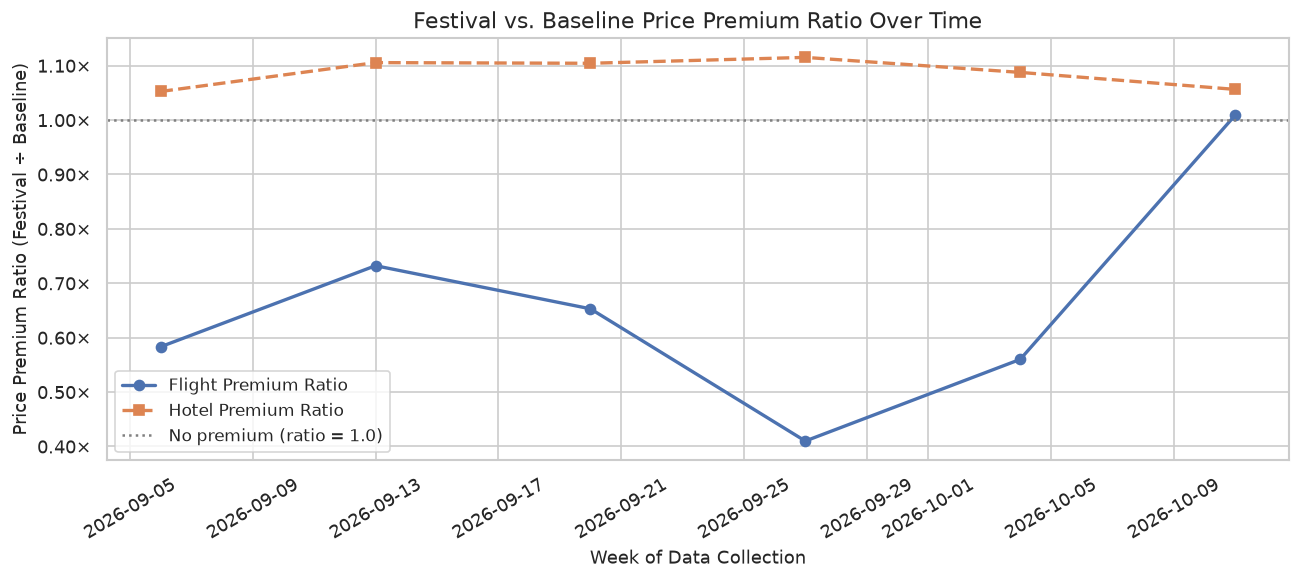

In [7]:
weekly_prem = df.set_index('date_collected').resample('W').agg({
    'flight_price_premium': 'mean',
    'hotel_price_premium': 'mean',
    'days_to_festival': 'min'
}).reset_index().dropna()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(weekly_prem['date_collected'], weekly_prem['flight_price_premium'],
        marker='o', color='#4C72B0', label='Flight Premium Ratio', lw=2)
ax.plot(weekly_prem['date_collected'], weekly_prem['hotel_price_premium'],
        marker='s', color='#DD8452', linestyle='--', label='Hotel Premium Ratio', lw=2)

ax.axhline(1.0, color='gray', linestyle=':', lw=1.5, label='No premium (ratio = 1.0)')
ax.set_title('Festival vs. Baseline Price Premium Ratio Over Time', fontsize=13)
ax.set_xlabel('Week of Data Collection', fontsize=11)
ax.set_ylabel('Price Premium Ratio (Festival ÷ Baseline)', fontsize=11)
ax.legend(fontsize=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.2f}×'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Observation
The hotel price premium ratio (orange) consistently exceeds the flight price premium ratio (blue) throughout the observation window. Hotel premiums generally stay well above 1.0×, meaning festival-date hotels are persistently more expensive than non-festival comparable dates. Flight premiums hover closer to 1.0×—festival-bound flights are only marginally pricier than typical routes most of the time, except during isolated spikes.

### Implication
The **largest festival cost burden comes from accommodation, not airfare**. A traveler focused only on finding a cheap flight may be surprised that hotels already carry a significant markup. This is actionable intelligence for budget planning: allocate more financial buffer for hotels than flights when estimating MassKara trip costs.

### Possible Action
Travel advisors and budget planners should communicate clearly: *“For MassKara, hotel costs drive the festival premium, not flights. Book accommodation early and set a firm budget ceiling for hotels—the flight fare is likely to stay near its typical range if you avoid the final 2-week window before the festival.”*

---
## Overall Takeaway

Across all five charts, the data tells a coherent story for MassKara Festival travelers:

| Signal | What It Means | What To Do |
|---|---|---|
| Google search interest ↑ | Prices become **volatile**, not universally higher | Don’t panic-book on buzz alone |
| High vs. low trend group | **Medians are equal** — only variance differs | Focus on timing, not hype |
| Days to festival ↓ | Flight prices **rise in the final 2 weeks** | Book flights ≥ 3 weeks before festival |
| Festival vs. baseline hotel | Hotels are **always priced at a premium** | Compare properties, not timing |
| Premium ratios | **Hotels carry higher markup** than flights | Budget more for accommodation |

**Bottom line for a traveler:** Book your flights 3–4 weeks before MassKara and spend your comparison energy on finding the best-value hotel, since that is where the festival surcharge is largest and most persistent.

---
*Milestone 4 — Initial Insights | Week 16*